In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import Masking, find_all_indices, hot_coding, visualize_Category_hist
from toolbox.loading import load_data
from toolbox.model import Model

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

### Data loading

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [38]:
class_task = "healthy_vs_cancer"
class_task = "cancer_vs_hbd"
# class_task = "MC"


Healthy vs. HDB

Non-cancer: 162 entries
Cancer: 96 entries


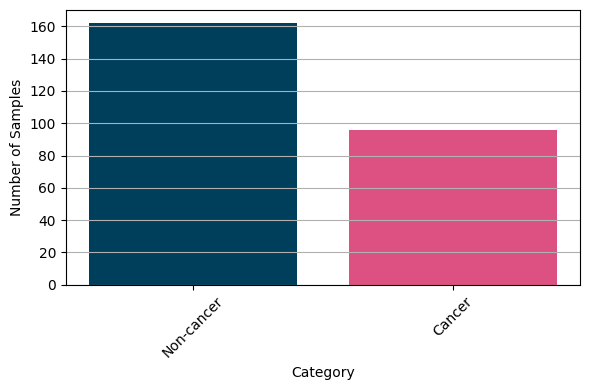

Available cases: ['Cancer' 'Non-cancer']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Non-cancer'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Non-cancer'}
(258, 31, 7728) (258, 2) (258,)


In [39]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    target_num_augmentation = 150


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
    target_num_augmentation = 150

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]
    target_num_augmentation = 100

visualize_Category_hist(labels)
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

### Train and test split

In [40]:
random_state = 0
n_folds = 5


def generate_folds(Case, n_folds, random_state):
    unique_patients = np.unique(Case)
    np.random.seed(random_state)

    # Check if Y is in one-hot encoding
    if len(Y.shape) == 1 or Y.shape[1] == 1:
        raise ValueError("Labels (Y) must be in one-hot encoding format")
    # Custom splitting to ensure 70/30 ratio
    patient_indices = np.arange(len(unique_patients))
    np.random.shuffle(patient_indices)

    # Split these indices into n_folds
    fold_size = len(patient_indices) // n_folds
    folds = []

    for i in range(n_folds):
        if i == n_folds - 1:
            # Last fold gets all remaining patients
            test_indices = patient_indices[i * fold_size :]
        else:
            test_indices = patient_indices[i * fold_size : (i + 1) * fold_size]
        # Training indices are all other indices
        train_indices = np.setdiff1d(patient_indices, test_indices)
        folds.append((train_indices, test_indices))

    return folds


folds = generate_folds(Case, n_folds, random_state)

### Masking and IIVV selection

In [41]:
# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]

Freq_sel = {
    "Top 2": top_freqs_baseline[:2],
    "Top 3": top_freqs_baseline[:3],
    "Top 5": top_freqs_baseline[:5],
    "Top 12": top_freqs_baseline[:12],
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "All": "all",
}

In [42]:
Fsel = "All"  # "Top 5"
Msel = "All"  # "Med. a+ ext."

mask.IIVV_mask(Mask_sel[Msel])

### Implementation of classification models

In [ ]:
stats_df = []
use_models = [
    "SVM",
    "RF",
    "LR",
    "DecisionTreeClassifier",
    "GradientBoostingClassifier",
]
output_prints = False

for random_state in range(1):
    print("random_state", random_state)
    folds = generate_folds(Case, n_folds, random_state)
    for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
        fold = fold_idx + 1

        # Get patient IDs for training and testing
        unique_patients = np.unique(Case)
        train_patients = unique_patients[train_patients_idx]
        test_patients = unique_patients[test_patients_idx]
        if output_prints:
            print("Train patients:", train_patients)
            print("Test patients:", test_patients)
        # Create masks for training and testing samples
        train_mask = np.isin(Case, train_patients)
        test_mask = np.isin(Case, test_patients)
        # Get training and testing data
        X_train, Y_train = X[train_mask], Y[train_mask]
        X_test, Y_test = X[test_mask], Y[test_mask]

        # here the frequency and IIVV selection is done
        X_train = X_train[:, Freq_sel[Fsel], :]
        X_test = X_test[:, Freq_sel[Fsel], :]
        # IIVV selection
        X_train = X_train[:, :, mask.mask]
        X_test = X_test[:, :, mask.mask]
        # Reshape
        X_train = X_train.reshape(X_train.shape[0], -1)
        X_test = X_test.reshape(X_test.shape[0], -1)

        # ------ Models ------
        for use_model in use_models:
            try:
                pf = Model(
                    use_model,
                    X_train,
                    Y_train,
                    X_test,
                    Y_test,
                    random_state,
                    inverse_mapping,
                    fold,
                    Msel,
                    Fsel,
                    class_task,
                )
                stats_df.append(pf)
            except:
                print(
                    "random state:",
                    random_state,
                    "for",
                    use_model,
                    "isn't working.",
                )
        # -----------------

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv", index=False)

random_state 0

Supported vector machine (SVM)



In [44]:
df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv")

In [45]:
# Suppose df_avg is your averaged DataFrame
metrics = ["ROC AUC", "Recall", "F1-score"]
df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

df_melt = df_avg.melt(
    id_vars=["Architecture"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",
)

df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

print("Average performance:\n", df_avg)

Average performance:
                  Architecture   ROC AUC    Recall  F1-score
0      DecisionTreeClassifier  0.728535  0.740600  0.744824
1  GradientBoostingClassifier  0.847256  0.754224  0.758544
2                          LR  0.830938  0.775212  0.777560
3                          RF  0.844693  0.771886  0.772035
4                         SVM  0.845389  0.794161  0.793513


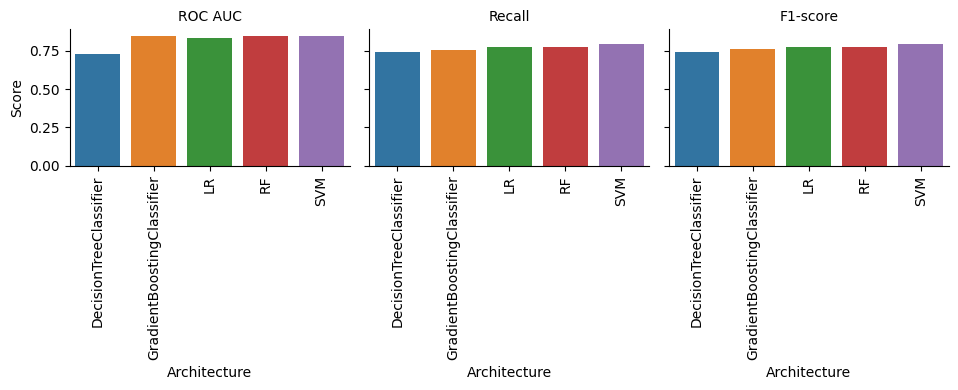

In [46]:
g = sns.catplot(
    data=df_melt,
    x="Architecture",
    y="Score",
    hue="Architecture",
    col="Metric",
    kind="bar",
    height=4,
    aspect=0.8,
)

g.set_titles("{col_name}")
g.set_axis_labels("Architecture", "Score")

# Rotate x tick labels
for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

___